# Методы оптимизации в машинном обучении

# Задание 1

In [1]:
!python -m pytest presubmit_tests.py::test_line_search

============================= test session starts ==============================
platform linux -- Python 3.13.5, pytest-9.0.2, pluggy-1.6.0
rootdir: /mnt/data/HW03_variant_executed/hw03_solution
plugins: anyio-4.13.0, ddtrace-4.4.0, Faker-40.1.2, asyncio-1.3.0, cov-7.0.0, json-report-1.5.0, metadata-3.1.1
asyncio: mode=Mode.STRICT, debug=False, asyncio_default_fixture_loop_scope=None, asyncio_default_test_loop_scope=function
collecting ... 

collected 1 item                                                               

presubmit_tests.py .                                                     [100%]

============================== 1 passed in 0.28s ===============================


# Задание 2

In [2]:
!python -m pytest presubmit_tests.py::test_gd_basic presubmit_tests.py::test_gd_1d

============================= test session starts ==============================
platform linux -- Python 3.13.5, pytest-9.0.2, pluggy-1.6.0
rootdir: /mnt/data/HW03_variant_executed/hw03_solution
plugins: anyio-4.13.0, ddtrace-4.4.0, Faker-40.1.2, asyncio-1.3.0, cov-7.0.0, json-report-1.5.0, metadata-3.1.1
asyncio: mode=Mode.STRICT, debug=False, asyncio_default_fixture_loop_scope=None, asyncio_default_test_loop_scope=function
collecting ... 

collected 2 items                                                              

presubmit_tests.py ..                                                    [100%]

============================== 2 passed in 0.27s ===============================


# Задание 3

/mnt/data/HW03_variant_executed/hw03_solution/plot_trajectory_2d.py:30: UserWarning: The following kwargs were not used by contour: 'linewidth'
  CS = plt.contour(X, Y, Z, levels=levels, colors='k', linewidth=4.0)


kappa = 1.0 method = Constant start = [2.5 2.5] iterations = 573 success
kappa = 1.0 method = Constant start = [-2.5  1.5] iterations = 573 success
kappa = 1.0 method = Armijo start = [2.5 2.5] iterations = 1 success
kappa = 1.0 method = Armijo start = [-2.5  1.5] iterations = 1 success


kappa = 1.0 method = Wolfe start = [2.5 2.5] iterations = 1 success
kappa = 1.0 method = Wolfe start = [-2.5  1.5] iterations = 1 success


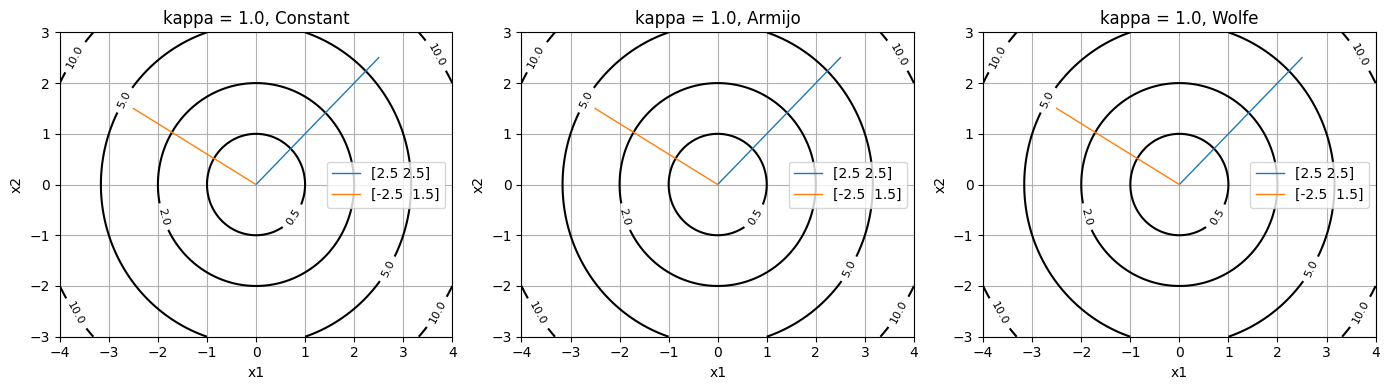

kappa = 10.0 method = Constant start = [2.5 2.5] iterations = 344 success
kappa = 10.0 method = Constant start = [-2.5  1.5] iterations = 394 success
kappa = 10.0 method = Armijo start = [2.5 2.5] iterations = 19 success
kappa = 10.0 method = Armijo start = [-2.5  1.5] iterations = 19 success
kappa = 10.0 method = Wolfe start = [2.5 2.5] iterations = 4 success
kappa = 10.0 method = Wolfe start = [-2.5  1.5] iterations = 3 success


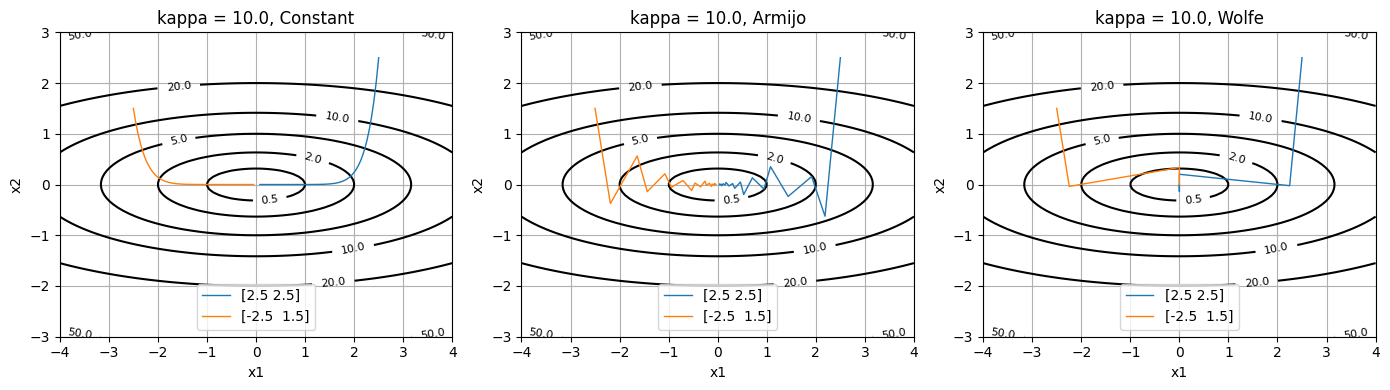

kappa = 100.0 method = Constant start = [2.5 2.5] iterations = 115 success
kappa = 100.0 method = Constant start = [-2.5  1.5] iterations = 166 success
kappa = 100.0 method = Armijo start = [2.5 2.5] iterations = 71 success
kappa = 100.0 method = Armijo start = [-2.5  1.5] iterations = 94 success
kappa = 100.0 method = Wolfe start = [2.5 2.5] iterations = 3 success
kappa = 100.0 method = Wolfe start = [-2.5  1.5] iterations = 3 success


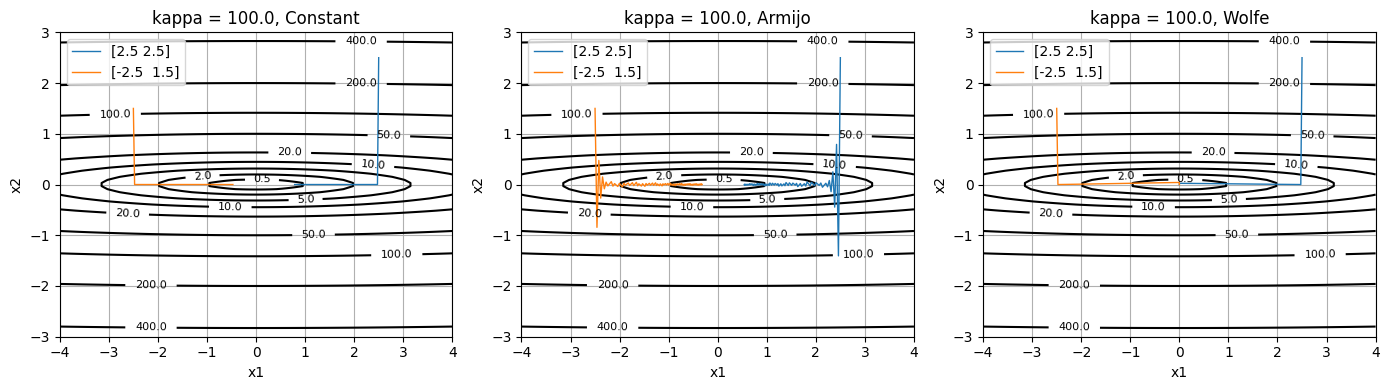

In [3]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from optimization import gradient_descent, newton
from oracles import QuadraticOracle
from plot_trajectory_2d import plot_levels, plot_trajectory

matrices = [np.diag([1.0, 1.0]), np.diag([1.0, 10.0]), np.diag([1.0, 100.0])]
starts = [np.array([2.5, 2.5]), np.array([-2.5, 1.5])]
methods = [{'method': 'Constant', 'c': 0.01}, {'method': 'Armijo'}, {'method': 'Wolfe'}]

for A in matrices:
    oracle = QuadraticOracle(A, np.zeros(2))
    plt.figure(figsize=(14, 4))
    for j in range(3):
        plt.subplot(1, 3, j + 1)
        plot_levels(oracle.func, xrange=[-4, 4], yrange=[-3, 3],
                    levels=[0.5, 2, 5, 10, 20, 50, 100, 200, 400])
        for x0 in starts:
            x, msg, history = gradient_descent(oracle, x0, tolerance=1e-5,
                    max_iter=1000, line_search_options=methods[j], trace=True)
            points = np.array(history['x'])
            plt.plot(points[:, 0], points[:, 1], '-', linewidth=1, label=str(x0))
            print('kappa =', A[1, 1], 'method =', methods[j]['method'],
                  'start =', x0, 'iterations =', len(history['func']) - 1, msg)
        plt.title('kappa = ' + str(A[1, 1]) + ', ' + methods[j]['method'])
        plt.xlabel('x1')
        plt.ylabel('x2')
        plt.legend()
    plt.tight_layout()
    plt.show()

**Вывод:** чем сильнее вытянуты линии уровня, тем сложнее градиентному спуску быстро найти минимум. Выбор шага влияет на траекторию.

# Задание 4

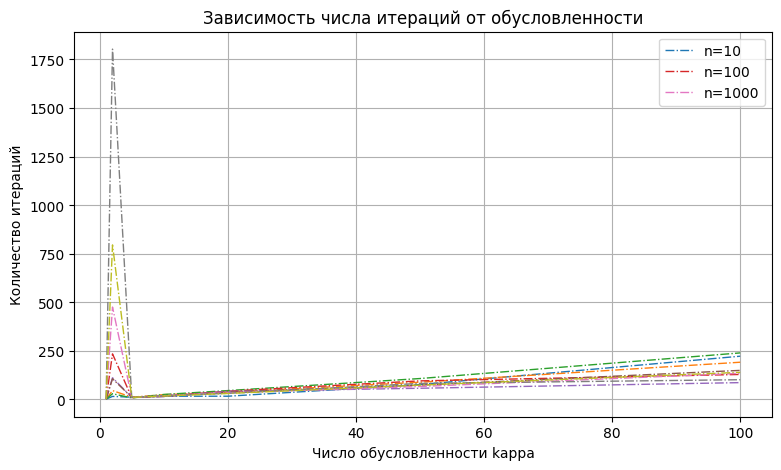

In [4]:
import scipy.sparse

np.random.seed(17)
sizes = [10, 100, 1000]
kappas = [1, 2, 5, 10, 20, 50, 100]
plt.figure(figsize=(9, 5))

for n in sizes:
    for repeat in range(3):
        iterations = []
        for kappa in kappas:
            diag = np.random.uniform(1, kappa, n)
            diag[0] = 1
            diag[-1] = kappa
            A = scipy.sparse.diags(diag)
            b = np.random.randn(n)
            oracle = QuadraticOracle(A, b)
            x, msg, history = gradient_descent(oracle, np.zeros(n),
                    tolerance=1e-5, max_iter=2000,
                    line_search_options={'method': 'Armijo'}, trace=True)
            iterations.append(len(history['func']) - 1)
        plt.plot(kappas, iterations, '-.', linewidth=1,
                 label='n=' + str(n) if repeat == 0 else None)
plt.xlabel('Число обусловленности kappa')
plt.ylabel('Количество итераций')
plt.title('Зависимость числа итераций от обусловленности')
plt.legend()
plt.grid()
plt.show()

**Вывод:** с ростом числа обусловленности число шагов обычно увеличивается. Для случайных матриц результаты немного различаются.

# Задание 5

In [5]:
!python -m pytest presubmit_tests.py::test_newton_basic presubmit_tests.py::test_newton_1d presubmit_tests.py::test_newton_fail

============================= test session starts ==============================
platform linux -- Python 3.13.5, pytest-9.0.2, pluggy-1.6.0
rootdir: /mnt/data/HW03_variant_executed/hw03_solution
plugins: anyio-4.13.0, ddtrace-4.4.0, Faker-40.1.2, asyncio-1.3.0, cov-7.0.0, json-report-1.5.0, metadata-3.1.1
asyncio: mode=Mode.STRICT, debug=False, asyncio_default_fixture_loop_scope=None, asyncio_default_test_loop_scope=function
collecting ... 

collected 3 items                                                              

presubmit_tests.py ...                                                   [100%]

============================== 3 passed in 0.31s ===============================


# Задание 6

## Логистическая регрессия

Используем логистическую функцию потерь с L2-регуляризацией. Градиент и гессиан вычисляются в `oracles.py`.

**Решение:** реализованы `func`, `grad`, `hess` в `LogRegL2Oracle`. Разностные производные нужны для проверки.

# Задание 7

In [6]:
!python -m pytest presubmit_tests.py::test_log_reg_usual presubmit_tests.py::test_grad_finite_diff_1 presubmit_tests.py::test_grad_finite_diff_2 presubmit_tests.py::test_hess_finite_diff_1 presubmit_tests.py::test_hess_finite_diff_2

============================= test session starts ==============================
platform linux -- Python 3.13.5, pytest-9.0.2, pluggy-1.6.0
rootdir: /mnt/data/HW03_variant_executed/hw03_solution
plugins: anyio-4.13.0, ddtrace-4.4.0, Faker-40.1.2, asyncio-1.3.0, cov-7.0.0, json-report-1.5.0, metadata-3.1.1
asyncio: mode=Mode.STRICT, debug=False, asyncio_default_fixture_loop_scope=None, asyncio_default_test_loop_scope=function
collecting ... 

collected 5 items                                                              

presubmit_tests.py .....                                                 [100%]

============================== 5 passed in 0.27s ===============================


# Задание 8

Ошибка градиента: 1.1295809899913177e-08
Ошибка гессиана: 4.463743049780612e-06
Ошибка градиента: 8.342371579563024e-09
Ошибка гессиана: 2.8146760678666016e-06
Набор: data/w8a.txt используемый размер: (2000, 60)
Градиентный спуск success итераций: 46
Ньютон success итераций: 3


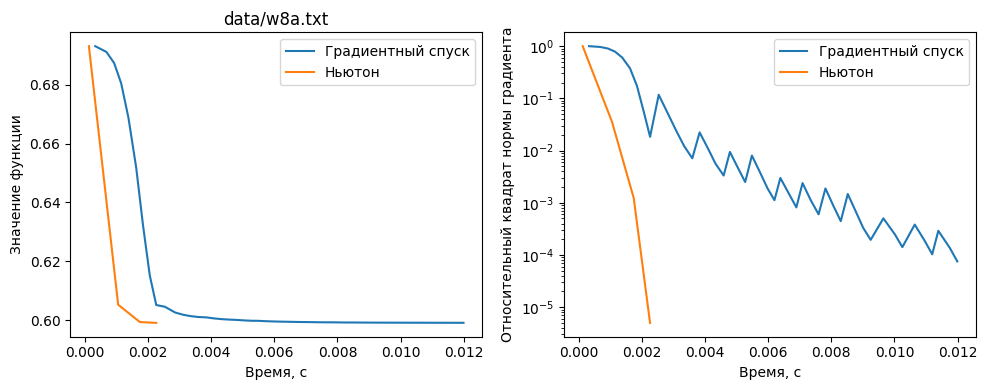

Набор: data/gisette_scale.bz2 используемый размер: (2000, 60)


Градиентный спуск success итераций: 1772
Ньютон success итераций: 3


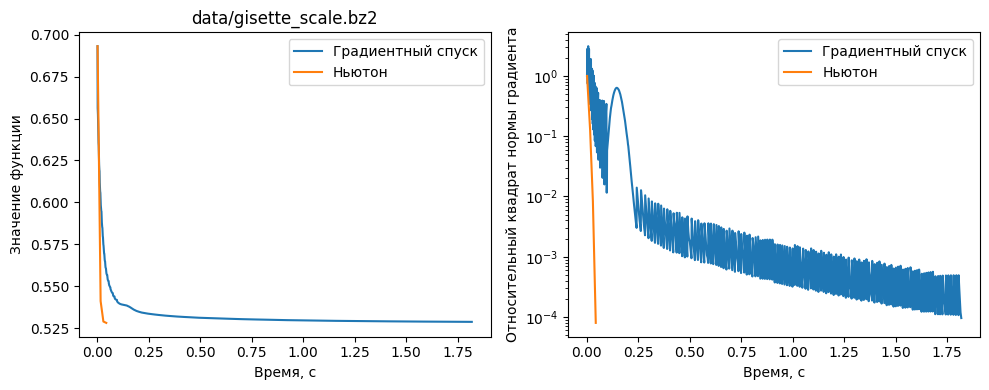

Набор: data/real-sim.bz2 используемый размер: (2000, 60)
Градиентный спуск success итераций: 13
Ньютон success итераций: 2


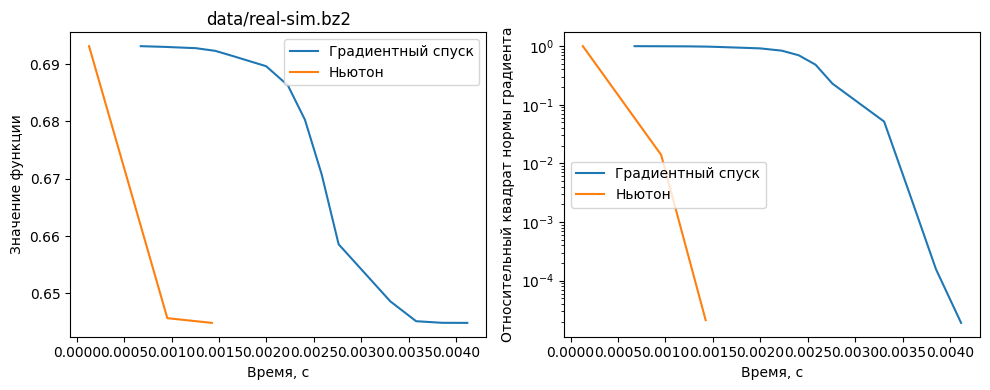

In [2]:
from sklearn.datasets import load_svmlight_file
from oracles import LogRegL2Oracle, grad_finite_diff, hess_finite_diff

# Проверка аналитических производных на маленьком примере
np.random.seed(17)
A = np.random.randn(8, 3)
b = np.random.choice([-1, 1], size=8)
oracle = LogRegL2Oracle(A, b, 0.1)
for x in [np.zeros(3), np.array([0.2, -0.1, 0.3])]:
    print('Ошибка градиента:', np.linalg.norm(oracle.grad(x) - grad_finite_diff(oracle.func, x)))
    print('Ошибка гессиана:', np.linalg.norm(oracle.hess(x) - hess_finite_diff(oracle.func, x)))

files = ['data/w8a.txt', 'data/gisette_scale.bz2', 'data/real-sim.bz2']

for filename in files:
    A, b = load_svmlight_file(filename)
    # Берём часть данных, чтобы метод Ньютона не работал слишком долго
    A = A[:2000, :60].tocsr()
    b = b[:2000]
    # В некоторых наборах метки 0/1, переводим их в -1/+1
    b = np.where(b > 0, 1, -1)
    m, n = A.shape
    oracle = LogRegL2Oracle(A, b, 1 / m)
    x0 = np.zeros(n)
    print('Набор:', filename, 'используемый размер:', A.shape)
    results = []
    # Ограничиваем число итераций, чтобы эксперимент завершался за разумное время.
    for name, method in [('Градиентный спуск', gradient_descent), ('Ньютон', newton)]:
        x, msg, history = method(oracle, x0, max_iter=3000, tolerance=1e-4, trace=True, line_search_options={"method": "Armijo"})
        results.append((name, history))
        print(name, msg, 'итераций:', len(history['func']) - 1)
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    for name, history in results:
        plt.plot(history['time'], history['func'], linewidth=1.5, label=name)
    plt.xlabel('Время, с')
    plt.ylabel('Значение функции')
    plt.title(filename)
    plt.legend()
    plt.subplot(1, 2, 2)
    for name, history in results:
        norms = np.array(history['grad_norm'])
        relative = norms**2 / norms[0]**2
        plt.semilogy(history['time'], relative, linewidth=1.5, label=name)
    plt.xlabel('Время, с')
    plt.ylabel('Относительный квадрат нормы градиента')
    plt.legend()
    plt.tight_layout()
    plt.show()

**Вывод:** Ньютон обычно сходится за меньшее число шагов, но вычисление гессиана делает шаг более дорогим. Эксперименты проведены на уменьшенных наборах данных.